# Iris Flower Classification Using Artificial Neural Networks (ANN)
###   A beginner-friendly Deep Learning project with Python, TensorFlow, and Keras

# 1. Import the required libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

# 2. Load the Iris dataset

In [4]:
from sklearn.datasets import load_iris

# Load Iris dataset
iris = load_iris(as_frame=True)

# Convert into DataFrame
df = iris.data.copy()

# Add target species names
df["Species"] = iris.target.map(
    dict(enumerate(iris.target_names))
)


In [5]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


# 3.Understand the dataset structure

In [6]:
df['Species'].value_counts()

Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


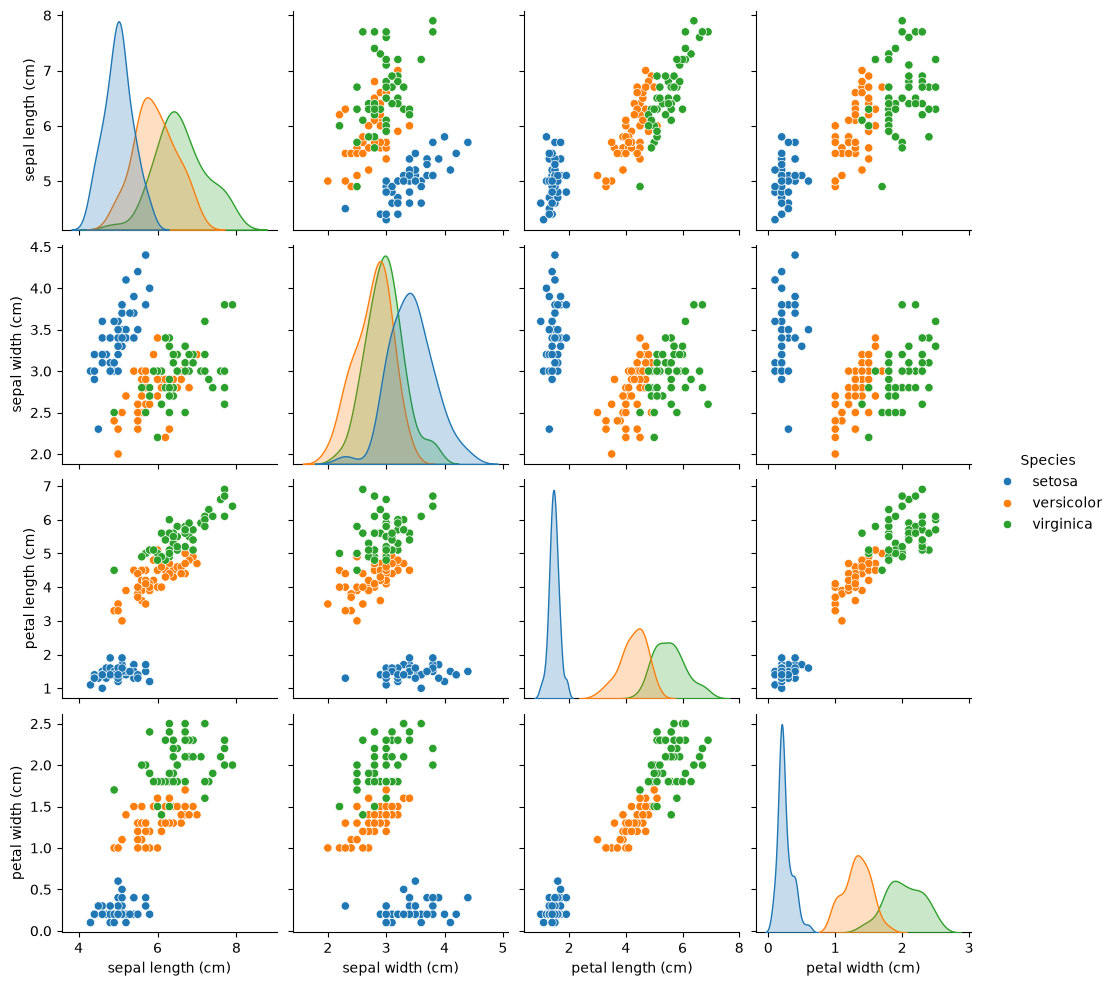

In [8]:
sns.pairplot(df,hue ='Species')

Missing values per column:


sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Species              0
dtype: int64


Species distribution:


Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

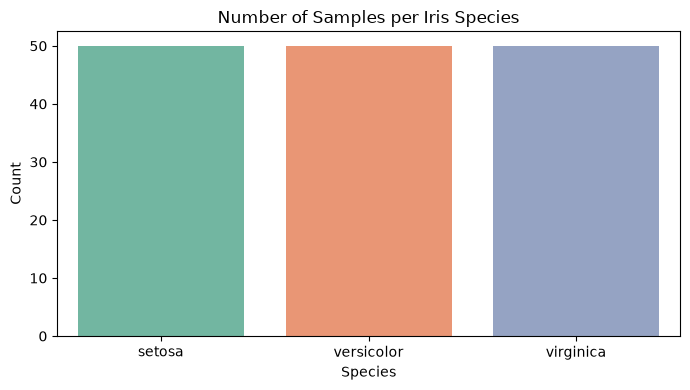

In [9]:
print("Missing values per column:")
display(df.isnull().sum())

print("\nSpecies distribution:")
display(df["Species"].value_counts())

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Species", hue="Species", palette="Set2", legend=False)
plt.title("Number of Samples per Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# 4.Separate input features (X) and target labels (y)

In [14]:
X = df.drop(columns=['Species'])
y = df['Species']

# 5.Encode the species labels

In [16]:
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# 6.Train-Test split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# 7. Standardize the input features

In [20]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# 8.Build a simple baseline: Perceptron 

In [21]:
per = Perceptron(max_iter = 1000,random_state=42)
per.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [23]:
y_pred_percep = per.predict(X_test_scaled)
accuracy_score(y_test,y_pred_percep)

0.8666666666666667

In [24]:
print(classification_report(y_test,y_pred_percep))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.88      0.70      0.78        10
           2       0.75      0.90      0.82        10

    accuracy                           0.87        30
   macro avg       0.88      0.87      0.87        30
weighted avg       0.88      0.87      0.87        30



# 9. Prepare labels for the ANN

In [26]:
num_classes = len(np.unique(y_train))
y_train_one_hot = to_categorical(y_train, num_classes=num_classes)
y_test_one_hot = to_categorical(y_test, num_classes=num_classes)

print("Integer label:", y_train[0])
print("One-hot label:", y_train_one_hot[0])

Integer label: 0
One-hot label: [1. 0. 0.]


# 10. Design the Artificial Neural Network (ANN)

In [28]:
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(16, activation="relu", name="hidden_layer_1"),
    Dense(8, activation="relu", name="hidden_layer_2"),
    Dense(num_classes, activation="softmax", name="output_layer")
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

# 11. Compile the model

In [29]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# 12. Train the ANN

In [30]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train_one_hot,
    epochs=150,
    batch_size=8,
    validation_split=0.20,
    callbacks=[early_stopping],
    verbose=1
)

print(f"Training stopped after {len(history.history['loss'])} epochs.")

Epoch 1/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.3958 - loss: 1.1436 - val_accuracy: 0.3750 - val_loss: 1.1180
Epoch 2/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5104 - loss: 1.0857 - val_accuracy: 0.5000 - val_loss: 1.0781
Epoch 3/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6354 - loss: 1.0305 - val_accuracy: 0.7083 - val_loss: 1.0372
Epoch 4/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7396 - loss: 0.9735 - val_accuracy: 0.7083 - val_loss: 0.9902
Epoch 5/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7812 - loss: 0.9066 - val_accuracy: 0.7083 - val_loss: 0.9291
Epoch 6/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8125 - loss: 0.8346 - val_accuracy: 0.7083 - val_loss: 0.8649
Epoch 7/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8333 - loss: 0.7675 - val_accuracy: 0.7500 - val_loss: 0.8082
Epoch 8/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8438 - loss: 0.7102 - val_accuracy: 0.7500 - v

In [32]:
loss, acc = model.evaluate(X_test_scaled,  y_test_one_hot, verbose=1)
print(acc)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.9333 - loss: 0.1067
0.9333333373069763


# 13. Visualize training and validation accuracy

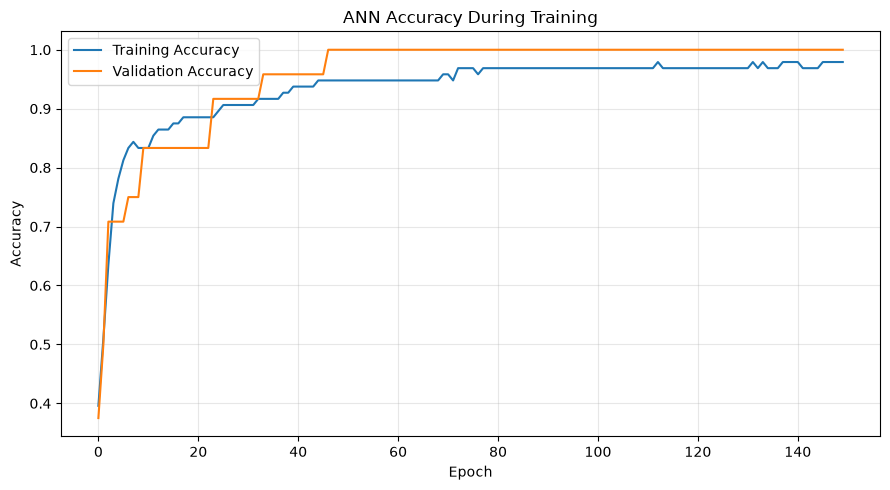

In [33]:
plt.figure(figsize=(9, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Accuracy During Training")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 14. Visualize training and validation loss

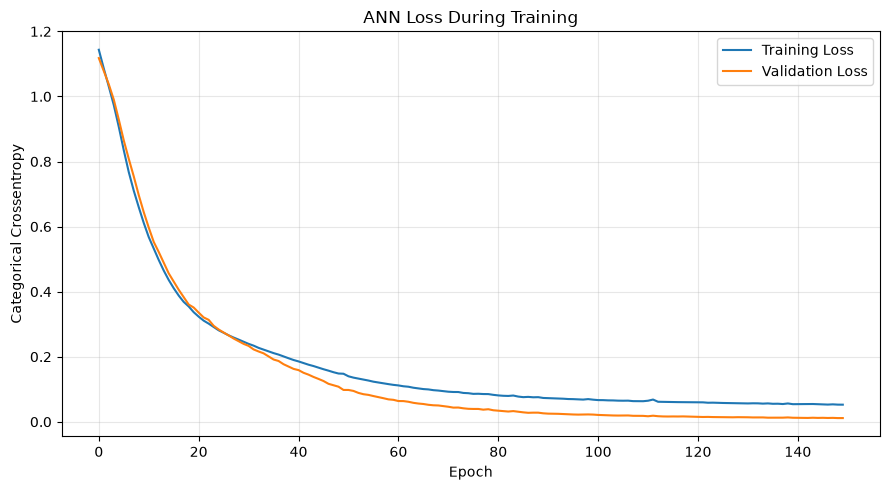

In [34]:
plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ANN Loss During Training")
plt.xlabel("Epoch")
plt.ylabel("Categorical Crossentropy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 15. Evaluate the ANN on unseen test data

In [35]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test_one_hot,
    verbose=0
)

print(f"ANN test loss: {test_loss:.4f}")
print(f"ANN test accuracy: {test_accuracy:.4f}")

ANN test loss: 0.1067
ANN test accuracy: 0.9333
